<a href="https://colab.research.google.com/github/20danaai/Learn_LibrariesPy/blob/main/03_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sklearn
from sklearn.datasets import make_circles

In [2]:
n_samples=1000
x,y=make_circles(n_samples,noise=0.05,random_state=42)

In [3]:
import pandas as pd
circles=pd.DataFrame({'x1':x[:,0],'x2':x[:,1],'label':y})
circles.head(10)

,x1,x2,label
0,0.742207,0.246686,1
1,-0.734032,0.168692,1
2,-0.829859,0.221959,1
3,-0.429136,0.672230,1
4,0.445602,-0.894936,0
5,-0.469885,0.708037,1
6,-0.016045,0.805623,1
7,0.759623,0.159526,1
8,-0.175692,-0.799837,1
9,-0.110616,1.042207,0


In [4]:
circles.label.value_counts()

,count
label,
1,500
0,500


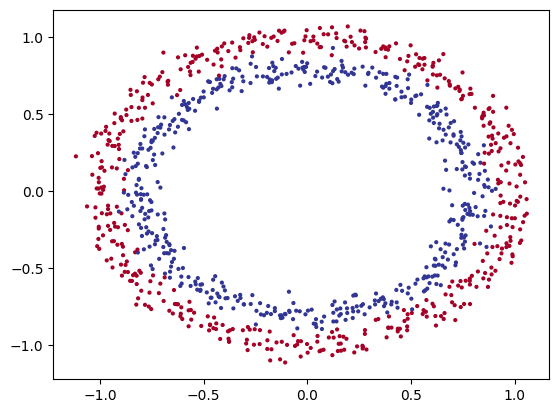

In [5]:

import matplotlib.pyplot as plt
plt.scatter(x=x[:,0],y=x[:,1],s=4,c=y,cmap=plt.cm.RdYlBu)


In [6]:
import torch
x=torch.from_numpy(x).type(torch.float32)
y=torch.from_numpy(y).type(torch.float32)

In [7]:
from sklearn.model_selection import train_test_split
x_train,y_train,x_test,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [8]:
len(x_train)

800

In [9]:
import torch
from torch import nn
device='cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [19]:
class circlemodel_v0(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer1=nn.Linear(2,5)
    self.layer2=nn.Linear(5,1)
  def forward(self,x:torch.tensor)->torch.tensor:
    return self.layer2(self.layer1(x))


In [20]:
model_0=circlemodel_v0().to(device)
model_0

circlemodel_v0(
  (layer1): Linear(in_features=2, out_features=5, bias=True)
  (layer2): Linear(in_features=5, out_features=1, bias=True)
)

In [18]:
model_0=nn.Sequential(
    nn.Linear(2,5),
    nn.Linear(5,1)
)
model_0

Sequential(
  (0): Linear(in_features=2, out_features=5, bias=True)
  (1): Linear(in_features=5, out_features=1, bias=True)
)